        # Lesson 8.3 · PyTorch Fundamentals
        ### Tensors, autograd, nn.Module, DataLoader and the canonical training loop

        | | |
        |---|---|
        | ⏱️ **Time** | about 100 minutes |
        | 📚 **Before you start** | Lesson 8.2 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Create and manipulate **tensors**; understand shape, dtype, broadcasting and device
- Use **autograd** to get gradients automatically (and verify them against Lesson 8.2)
- Build models with **`nn.Module`**, train with **`DataLoader`**, **loss functions** and **optimisers**
- Write the five-line **training loop** from memory, and explain epochs and batch size

> 🌾 **The story so far.** In Lesson 8.2 you wrote the calculus by hand. Now we let PyTorch do the bookkeeping, and because you *know* what's underneath, every line will feel familiar.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Tensors: NumPy arrays with superpowers

A **tensor** is an n-dimensional array that can (a) live on a GPU and (b) remember how it was computed so gradients can flow back.

| Rank | Name | Example shape | Example |
|---|---|---|---|
| 0 | scalar | `()` | the loss |
| 1 | vector | `(5,)` | five weekly prices |
| 2 | matrix | `(32, 16)` | a batch of 32 samples × 16 features |
| 3 | 3-D | `(32, 52, 4)` | batch × weeks × features (sequences) |
| 4 | 4-D | `(32, 3, 48, 48)` | batch × channels × height × width (images) |

In [2]:
a = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
print("shape:", a.shape, "| dtype:", a.dtype, "| device:", a.device)
print("zeros:", torch.zeros(2, 2).tolist(), "| random normal:", torch.randn(2, 2).shape, "| arange:", torch.arange(5))

# arithmetic is element-wise; @ is matrix multiplication
print("a * 2 =", (a * 2).tolist(), "| a @ a.T =", (a @ a.T).tolist())

# broadcasting: a (2,3) tensor minus a (3,) vector subtracts the vector from every row
col_means = a.mean(dim=0)
print("column means:", col_means.tolist(), "-> centred:", (a - col_means).tolist())

# NumPy bridge (shares memory on CPU!)
n = a.numpy(); t = torch.from_numpy(np.array([1.5, 2.5]))
print("to numpy:", type(n).__name__, "| from numpy dtype:", t.dtype)

shape: torch.Size([2, 3]) | dtype: torch.float32 | device: cpu
zeros: [[0.0, 0.0], [0.0, 0.0]] | random normal: torch.Size([2, 2]) | arange: tensor([0, 1, 2, 3, 4])
a * 2 = [[2.0, 4.0, 6.0], [8.0, 10.0, 12.0]] | a @ a.T = [[14.0, 32.0], [32.0, 77.0]]
column means: [2.5, 3.5, 4.5] -> centred: [[-1.5, -1.5, -1.5], [1.5, 1.5, 1.5]]
to numpy: ndarray | from numpy dtype: torch.float64


**Three habits that prevent 80 % of PyTorch bugs**

1. **Print shapes constantly.** Most errors are shape errors.
2. **dtype matters**: model weights are `float32`; NumPy defaults to `float64` (convert with `.float()`); class labels for `CrossEntropyLoss` must be `int64` (`.long()`).
3. **Device matters**: tensors that interact must be on the same device (`.to(device)`).

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
print("training device:", device)

training device: cpu


---
### 🧩 Exercise 1: Standardise a batch with broadcasting  ⭐

`X` below is a `(6, 3)` tensor of features. Standardise **each column** to mean 0 and standard deviation 1
(use `unbiased=False`, i.e. population std) without a loop, storing the result in `X_std`. Also compute `row_sums`: the sum of each **row** (shape `(6,)`).

<details><summary>💡 Hint 1: gentle nudge</summary>

`X.mean(dim=0)` averages down the rows, giving one mean per column.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`X.std(dim=0, unbiased=False)` likewise for std.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`X_std = (X - mean) / std`: broadcasting handles the shapes. `row_sums = X.sum(dim=1)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
torch.manual_seed(0)
X = torch.randn(6, 3) * torch.tensor([1., 10., 100.]) + torch.tensor([0., 5., 50.])
X_std = None
row_sums = None

In [ ]:
try:
    ag.check("X_std has shape (6, 3)", X_std is not None and tuple(X_std.shape) == (6, 3))
    ag.check("each column has mean ~0", X_std is not None and torch.allclose(X_std.mean(dim=0), torch.zeros(3), atol=1e-5))
    ag.check("each column has std ~1", X_std is not None and torch.allclose(X_std.std(dim=0, unbiased=False), torch.ones(3), atol=1e-5))
    ag.check("row_sums has shape (6,)", row_sums is not None and tuple(row_sums.shape) == (6,))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 2 · Autograd: back-propagation for free

Set `requires_grad=True` and PyTorch records every operation in a **computational graph**. Call `.backward()` on a scalar loss and every leaf tensor gets a `.grad`: exactly the chain-rule bookkeeping of Lesson 8.2.

Reproduce our worked example ($x=2$, $w_1=0.5$, $b_1=0$, $w_2=-1$, $y=1$; hand-computed gradients 8, 4, −4):

In [6]:
x, y_true = torch.tensor(2.0), torch.tensor(1.0)
w1 = torch.tensor(0.5, requires_grad=True); b1 = torch.tensor(0.0, requires_grad=True); w2 = torch.tensor(-1.0, requires_grad=True)

h = torch.relu(w1 * x + b1)
loss = (w2 * h - y_true) ** 2
loss.backward()
print(f"loss = {loss.item()} | dL/dw1 = {w1.grad.item()} | dL/db1 = {b1.grad.item()} | dL/dw2 = {w2.grad.item()}   (hand: 8, 4, -4)")

loss = 4.0 | dL/dw1 = 8.0 | dL/db1 = 4.0 | dL/dw2 = -4.0   (hand: 8, 4, -4)


Three autograd rules to remember:

| Rule | Why |
|---|---|
| **Gradients accumulate** (`.grad += new`) | So call `optimizer.zero_grad()` before every `backward()`: the #1 beginner bug |
| `with torch.no_grad():` | Turns recording off for evaluation/inference: faster, less memory |
| `.detach()` | Cuts a tensor out of the graph (e.g. before plotting or `.numpy()`) |

In [7]:
w = torch.tensor(1.0, requires_grad=True)
for i in range(3):
    (w * 3).backward()
    print(f"after backward #{i+1}: w.grad = {w.grad.item()}   <- accumulating!")
w.grad.zero_(); print("after zero_():", w.grad.item())

after backward #1: w.grad = 3.0   <- accumulating!
after backward #2: w.grad = 6.0   <- accumulating!
after backward #3: w.grad = 9.0   <- accumulating!
after zero_(): 0.0


---
### 🧩 Exercise 2: Let autograd differentiate  ⭐

Let `w = torch.tensor([1.0, -2.0], requires_grad=True)`, `x = torch.tensor([3.0, 4.0])`, target `t = 5.0`.
Define `loss = (w @ x - t) ** 2`, call `backward()`, and store a **copy** of the gradient in `grad_auto` (`w.grad.clone()`).
Then compute the analytic gradient yourself, `grad_hand = 2 * (w·x − t) * x`, and confirm they match.

<details><summary>💡 Hint 1: gentle nudge</summary>

`pred = w @ x` is a scalar tensor (1·3 + (−2)·4 = −5).

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`loss.backward()` populates `w.grad`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`grad_hand = 2 * (w.detach() @ x - t) * x`: use `.detach()` so no graph is built.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
w = torch.tensor([1.0, -2.0], requires_grad=True)
x = torch.tensor([3.0, 4.0]); t = 5.0
grad_auto = None
grad_hand = None

In [ ]:
try:
    ag.check("gradient is [-60, -80]", grad_auto is not None and torch.allclose(grad_auto, torch.tensor([-60., -80.])))
    ag.check("hand gradient matches autograd", grad_hand is not None and torch.allclose(grad_auto, grad_hand))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 3 · `nn.Module`: building blocks

A model is a class that (1) declares layers in `__init__`, (2) defines the computation in `forward`. PyTorch finds the parameters automatically.

In [10]:
class PriceMLP(nn.Module):
    def __init__(self, n_in, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

m = PriceMLP(15)
print(m)
print("trainable parameters:", sum(p.numel() for p in m.parameters() if p.requires_grad))
for name, p in m.named_parameters(): print(f"  {name:12s} {tuple(p.shape)}")

PriceMLP(
  (net): Sequential(
    (0): Linear(in_features=15, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
trainable parameters: 1601
  net.0.weight (32, 15)
  net.0.bias   (32,)
  net.2.weight (32, 32)
  net.2.bias   (32,)
  net.4.weight (1, 32)
  net.4.bias   (1,)


`nn.Linear(n_in, n_out)` = the dense layer of Lesson 8.2 (weights `(n_out, n_in)`, bias `(n_out,)`). `nn.Sequential` chains layers. Other layers you'll meet:
`nn.Conv2d`, `nn.LSTM`, `nn.Dropout`, `nn.BatchNorm1d`, `nn.Embedding`, `nn.TransformerEncoder`.

**Loss functions: pay attention to what each expects**

| Loss | Task | Input | Pitfall |
|---|---|---|---|
| `nn.MSELoss()` | regression | predictions, targets (same shape) | targets must be `float` |
| `nn.L1Loss()` / `nn.HuberLoss()` | robust regression | same | |
| `nn.BCEWithLogitsLoss()` | binary | **raw logits**, float targets 0/1 | do **not** apply sigmoid first |
| `nn.CrossEntropyLoss()` | multi-class | **raw logits** `(n, classes)`, targets = **class indices** (`long`) | do **not** apply softmax first; not one-hot |

---
### 🧩 Exercise 3: CrossEntropyLoss, demystified  ⭐⭐

Given `logits` (shape `(3, 4)`) and class indices `labels = [2, 0, 3]`:
1. compute `ce_torch = nn.CrossEntropyLoss()(logits, labels)`.
2. compute `ce_manual` yourself: softmax over each row, take the probability of the true class, average `-log`.
They must agree.

<details><summary>💡 Hint 1: gentle nudge</summary>

`probs = torch.softmax(logits, dim=1)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Pick the true-class probabilities with `probs[torch.arange(3), labels]`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`ce_manual = -torch.log(picked).mean()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
torch.manual_seed(1)
logits = torch.randn(3, 4)
labels = torch.tensor([2, 0, 3])
ce_torch = None
ce_manual = None

In [ ]:
try:
    ag.check("both computed", ce_torch is not None and ce_manual is not None)
    ag.check("manual equals PyTorch (CrossEntropyLoss = softmax + NLL in one)", ce_torch is not None and ce_manual is not None and torch.isclose(ce_torch, ce_manual, atol=1e-6))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 4 · Data: `Dataset` and `DataLoader`

A `DataLoader` slices the data into **mini-batches**, shuffles each epoch, and can load in parallel. We'll use it on a real task:
predict the **4-week-ahead log price change** for tomatoes from the Phase 7 feature table (momentum, volatility, season, rain).
Splits are chronological.

In [13]:
y_price = ag.price_series("tomato", "Central", "W")
rain9 = ag.load_weather().set_index("date")["rainfall_mm"].resample("W").sum().reindex(y_price.index).rolling(9, min_periods=1).sum()
tab = ag.make_origin_table(y_price, 4, pd.DataFrame({"rain_9w": rain9})).dropna()
feat_cols = [c for c in tab.columns if c != "target"]

n_tr, n_va = int(len(tab) * 0.65), int(len(tab) * 0.15)
tr, va, te = tab.iloc[:n_tr], tab.iloc[n_tr + 4:n_tr + n_va], tab.iloc[n_tr + n_va + 4:]          # 4-week embargo between blocks
mu, sd = tr[feat_cols].mean(), tr[feat_cols].std()                                                 # TRAIN statistics only
to_t = lambda d: (torch.tensor(((d[feat_cols] - mu) / sd).to_numpy(), dtype=torch.float32), torch.tensor(d["target"].to_numpy(), dtype=torch.float32))
(Xtr, ytr), (Xva, yva), (Xte, yte) = to_t(tr), to_t(va), to_t(te)
print("shapes:", tuple(Xtr.shape), tuple(Xva.shape), tuple(Xte.shape))

loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True)
xb, yb = next(iter(loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(loader))

shapes: (303, 15) (66, 15) (90, 15)
one batch: (32, 15) (32,) | batches per epoch: 10


## 5 · The canonical training loop

```
for epoch in range(n_epochs):
    for xb, yb in loader:
        optimizer.zero_grad()          # 1. forget old gradients
        pred = model(xb)               # 2. forward pass
        loss = loss_fn(pred, yb)       # 3. how wrong?
        loss.backward()                # 4. back-propagate
        optimizer.step()               # 5. update the weights
```
Memorise it: **zero, forward, loss, backward, step.** Everything else in this phase is decoration around these five lines.

Switch modes: `model.train()` (dropout/batch-norm active) vs `model.eval()` (deterministic), and wrap evaluation in `torch.no_grad()`.

final train MAE 0.0179 | best validation MAE 0.1142 at epoch 11


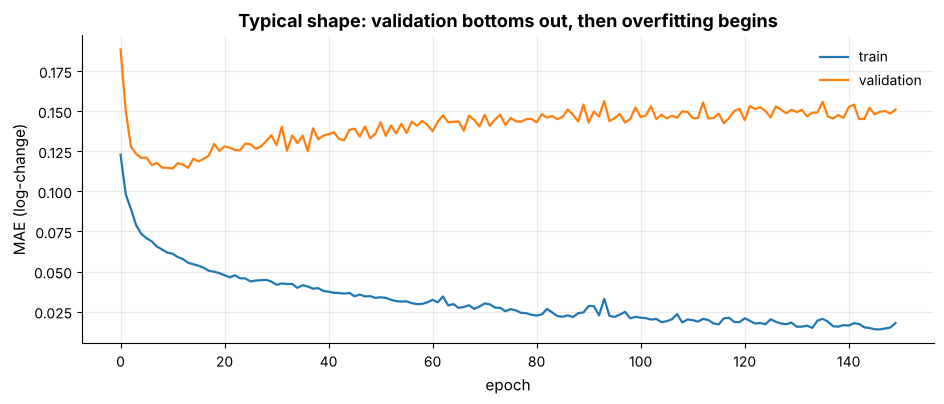

In [14]:
torch.manual_seed(0)
model = PriceMLP(len(feat_cols)).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.L1Loss()                                          # MAE: robust and matches our reporting metric

hist = []
for epoch in range(150):
    model.train()
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        hist.append((loss_fn(model(Xtr.to(device)), ytr.to(device)).item(), loss_fn(model(Xva.to(device)), yva.to(device)).item()))
hist = np.array(hist)
print(f"final train MAE {hist[-1, 0]:.4f} | best validation MAE {hist[:, 1].min():.4f} at epoch {hist[:, 1].argmin() + 1}")
plt.plot(hist[:, 0], label="train"); plt.plot(hist[:, 1], label="validation"); plt.xlabel("epoch"); plt.ylabel("MAE (log-change)"); plt.legend()
plt.title("Typical shape: validation bottoms out, then overfitting begins"); plt.show()

Is that any good? Context is everything: compare with a zero-change forecast and Ridge on the **same** test block:

In [15]:
from sklearn.linear_model import Ridge
ridge = Ridge(10).fit(Xtr.numpy(), ytr.numpy())
model.eval()
with torch.no_grad():
    mlp_pred = model(Xte.to(device)).cpu().numpy()
print(f"test MAE (log-change):  zero-change {ag.mae(yte.numpy(), 0*mlp_pred):.4f} | Ridge {ag.mae(yte.numpy(), ridge.predict(Xte.numpy())):.4f} | MLP (last epoch) {ag.mae(yte.numpy(), mlp_pred):.4f}")

test MAE (log-change):  zero-change 0.1298 | Ridge 0.0732 | MLP (last epoch) 0.0972


The MLP at epoch 150 has started to overfit (see the curves), so a plain linear model competes. Lesson 8.4 shows *how* to fix that: early stopping, dropout, weight decay, schedulers.
**Lesson in humility #1 of deep learning: always report the simple baseline next to your network.**

---
### 🧩 Exercise 4: Write `train_epoch`  ⭐⭐

Implement `train_epoch(model, loader, loss_fn, optimizer)` that runs **one epoch** of the five-step loop in `train()` mode and returns the **mean loss over batches** (a float).
Then train a fresh `PriceMLP` for 30 epochs with Adam (lr 1e-3) and the MSE loss, recording the epoch losses in `epoch_losses`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Start with `model.train()`, an empty list of batch losses, then loop over the `loader`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Inside: `optimizer.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); optimizer.step(); losses.append(loss.item())`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Return `float(np.mean(losses))`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def train_epoch(model, loader, loss_fn, optimizer):
    return None

torch.manual_seed(0)
m2 = PriceMLP(len(feat_cols))
epoch_losses = []

In [ ]:
try:
    ag.check("30 epoch losses", len(epoch_losses) == 30 and all(isinstance(v, float) for v in epoch_losses))
    ag.check("training loss fell by at least 30 %", len(epoch_losses) == 30 and epoch_losses[-1] < 0.7 * epoch_losses[0])
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 6 · Epochs, batch size, and saving your work

| Knob | Too small | Too large |
|---|---|---|
| **Epochs** | underfit (the model hasn't learned yet | overfit) memorises noise (use early stopping) |
| **Batch size** | noisy gradients, slower per epoch, but regularising | smooth gradients, memory-hungry, can generalise worse |
| **Learning rate** | slow | divergence |

Save and restore a model with its `state_dict` (the dictionary of all parameters):

In [18]:
import tempfile, os
path = os.path.join(tempfile.gettempdir(), "price_mlp.pt")
torch.save(model.state_dict(), path)
clone = PriceMLP(len(feat_cols)); clone.load_state_dict(torch.load(path)); clone.eval()
with torch.no_grad():
    same = torch.allclose(clone(Xte), model.cpu()(Xte))
print("restored model gives identical predictions:", same)

restored model gives identical predictions: True


## 🎓 Mini-quiz
1. What does `optimizer.zero_grad()` prevent?
2. You apply `softmax` in your model's last layer *and* use `nn.CrossEntropyLoss`. What's wrong?
3. Shape of a batch of 64 RGB images of 48×48 pixels in PyTorch?

<details><summary>Answers</summary>

1. Gradients from the previous batch accumulating into the current one. 2. CrossEntropyLoss already applies log-softmax; doing it twice squashes gradients and hurts learning: output raw logits. 3. `(64, 3, 48, 48)`: channels first.
</details>

        ---
        ## 🧾 Recap
        - Tensors = GPU-capable arrays; watch **shape, dtype, device**.
- **Autograd** records operations and `.backward()` fills `.grad`: verified against our hand-derived 8, 4, −4.
- Models subclass **`nn.Module`**; **`DataLoader`** makes shuffled mini-batches.
- The loop: **zero_grad → forward → loss → backward → step**; `model.train()` / `model.eval()` + `torch.no_grad()` for evaluation.
- Loss pitfalls: `CrossEntropyLoss` wants **logits** and **class indices**; `BCEWithLogitsLoss` wants **logits**.

**Next up:** Lesson 8.4: making networks train *well*: optimisers, learning-rate schedules, dropout, batch normalisation, regularisation and early stopping.